# Использование предобученных моделей  (Transfer Learning)

Задание: загрузить датасет и использовать перенос обучения для решения задачи классификации.

## Порядок выполнения

1. Загрузить датасет ;
1. Подготовить transforms, DataSet и DataLoader;
1. Выбрать одну из моделей
Список предобученных моделей в Pytorch.(https://pytorch.org/vision/stable/models.html#classification)
1. Использовать на этой модели прием выделения признаков;
1. Использовать на этой модели прием дообучения (fine-tune);
1. Оценить результаты лучшей модели на тестовой выборке.
Написать выводы по итогам работы.




In [ ]:
import os
from tqdm.autonotebook import tqdm, trange

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler

import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import copy
import matplotlib.pyplot as plt
import PIL
import random


%matplotlib inline

<ipython-input-1-52a54a514ba7>:2: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Копируем файл из Google Drive в рабочую директорию Colab
!cp /content/drive/MyDrive/hymenoptera_data.zip /content/

# Распаковываем архив
!unzip -qo /content/hymenoptera_data.zip -d /content/data/

# Проверяем содержимое
!ls /content/data/hymenoptera_data

train  val


In [ ]:
os.listdir('/content/data')

['hymenoptera_data']

In [ ]:
print(os.listdir('/content/data/hymenoptera_data'))

['val', 'train']


In [ ]:
print(os.listdir('/content/data/hymenoptera_data/train'))

['ants', 'bees']


In [ ]:
print(os.listdir('/content/data/hymenoptera_data/val'))
# муравьи, пчелы

['ants', 'bees']


## Создание Dataset и DataLoader

По аналогии с прошлыми заданиями требуется создать transforms, которые передаются в создаваемый Dataset и из датасета  создаете DataLoaders.

Можно использовать:

- v2.ToImage()
- v2.Resize() или v2.RandomResizedCrop() - размер изображения после кадрирования, должен быть равен размеру ожидаемому на ходе предобученной модели.
- v2.RandomRotation()
- v2.RandomHorizontalFlip()
- v2.ToDtype()

[Описания в документации](https://pytorch.org/vision/stable/transforms.html#v2-api-reference-recommended)

Размеры данных: {'train': 244, 'val': 153}
Классы: ['ants', 'bees']
Используемое устройство: cpu


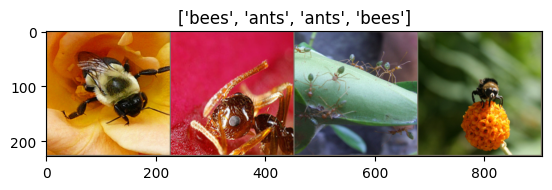

In [ ]:
# Аугментация обучающих данных для расширения обучающей выборки и её нормализация
# Для валидационной (тестовой) выборки только нормализация

# Определение transforms для данных
data_transforms = {
    'train': transforms.Compose([
        # Случайное изменение размера
        transforms.RandomResizedCrop(224),
        # Случайное горизонтальное отражение
        transforms.RandomHorizontalFlip(),
        # Преобразование в тензор
        transforms.ToTensor(),
        # Нормализация с использованием среднего и стандартного отклонения
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        # Изменение размера
        transforms.Resize(256),
        # Центральная обрезка
        transforms.CenterCrop(224),
        # Преобразование изображения в тензор
        transforms.ToTensor(),
        # Нормализация изображения с использованием среднего и стандартного отклонения
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = '/content/data/hymenoptera_data'

# Создание Dataset
image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
    for x in ['train', 'val']
}

# Создание DataLoader
dataloaders = {
    x: torch.utils.data.DataLoader(
        image_datasets[x],  # Используем соответствующий Dataset
        batch_size=4,
        shuffle=True if x == 'train' else False,  # Перемешивание данных только для обучающего набора
        num_workers=2
    )
    for x in ['train', 'val']
}

# Проверка размеров данных
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

print(f"Размеры данных: {dataset_sizes}")
print(f"Классы: {class_names}")

# Определение устройства (GPU или CPU)
use_gpu = torch.cuda.is_available()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

# Визуализация данных
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

inputs, classes = next(iter(dataloaders['train']))

out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

# Извлечение признаков

## Прием извлечения признаков

Этот прием может использоваться как сам по себе, так и быть предварительным этапом для дообучения.

Он заключается в том, что заменяется полносвязная часть модели (head/голова) на свою с учетом размерностей выходных данных из сверточной части и количеством классов в текущей задаче. Перед обучением требуется "заморозить" параметры сверточных слоев.



[Список](https://pytorch.org/vision/stable/models.html#classification)

1.   Новый пункт
2.   Новый пункт

предобученных моделей в Pytorch.

### Загрузка модели
У модели можно использовать метод .parameters(), он возвращает итерируемый объект с параметрами вашей модели, (можно их перебрать и отключить необходимость расчета градиентов).

In [ ]:
# Загрузка предобученной модели ResNet-18
model_conv = models.resnet18(pretrained=True)

# Замораживаем все параметры модели
for param in model_conv.parameters():
    param.requires_grad = False

# Заменяем полносвязный слой на новый
num_classes = 2
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, num_classes)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model_conv = model_conv.to(device)

# Функция потерь
loss_fn = nn.CrossEntropyLoss()

# В оптимизаторе обучаем только параметры последнего слоя
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Изменяем скорость обучения
# Уменьшение LR в 0,1 раза каждые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

In [ ]:
# Загрузка предобученной модели ResNet-50
model_resnet50 = models.resnet50(pretrained=True)

# Замораживаем все параметры модели
for param in model_resnet50.parameters():
    param.requires_grad = False

# Заменяем полносвязный слой на новый
num_ftrs = model_resnet50.fc.in_features
model_resnet50.fc = nn.Linear(num_ftrs, num_classes)

# Перемещаем модель на устройство
model_resnet50 = model_resnet50.to(device)

# Обучаем только параметры последнего слоя
optimizer_resnet50 = optim.SGD(model_resnet50.fc.parameters(), lr=0.001, momentum=0.9)

# Измененяем скорость обучения
# Уменьшение LR в 0,1 раза каждые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_resnet50, step_size=7, gamma=0.1)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 132MB/s]


In [ ]:
# Загрузка предобученной модели EfficientNet-B0
model_efficientnet = models.efficientnet_b0(pretrained=True)

# Замораживаем все параметры модели
for param in model_efficientnet.parameters():
    param.requires_grad = False

# Заменяем классификатор на новый
num_ftrs = model_efficientnet.classifier[1].in_features
model_efficientnet.classifier[1] = nn.Linear(num_ftrs, num_classes)

# Перемещаем модель на устройство
model_efficientnet = model_efficientnet.to(device)

# Обучаем только параметры последнего слоя
optimizer_efficientnet = optim.SGD(model_efficientnet.classifier[1].parameters(), lr=0.001, momentum=0.9)

# Измененяем скорость обучения
# Уменьшение LR в 0,1 раза каждые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_efficientnet, step_size=7, gamma=0.1)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 73.0MB/s]


В этой работе также рассмотрим применение планировщика для изменения скорости обучения. Ранее скорость обучения была константой, теперь же в процессе обучения каждые n эпох будем ее снижать.

### ### Обучение и тестирование

Несколько эпох обучите модель в таком состоянии. Для обучения используйте цикл с эпохами и перебором dataloader, но к нему в цикл эпох требуется добавить шаг планировщика scheduler.step().

Функция обучения с переключением режимов моделей (model.train(), model.eval()), так как теперь в них может быть пакетная нормализация и используйте контекст torch.no_grad() при проверке модели.

In [ ]:
def train_model(model, loss_fn, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Сохраняем веса лучшей модели
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    # Цикл по эпохам
    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Устанавливаем модель в режим обучения
            else:
                model.eval()   # Устанавливаем модель в режим оценки

            running_loss = 0.0  # Накопление потерь
            running_corrects = 0  # Накопление правильных предсказаний

            # Итерация по данным
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)  # Перемещаем данные на устройство
                labels = labels.to(device)  # Перемещаем метки на устройство

                # Обнуляем градиенты параметров
                optimizer.zero_grad()

                # Прямой проход
                with torch.set_grad_enabled(phase == 'train'):  # Включаем градиенты только в режиме обучения
                    outputs = model(inputs)  # Получаем предсказания модели
                    _, preds = torch.max(outputs, 1)  # Получаем предсказанные классы
                    loss = loss_fn(outputs, labels)  # Вычисляем потери

                    # Обратный проход и оптимизация только в режиме обучения
                    if phase == 'train':
                        loss.backward()  # Вычисляем градиенты
                        optimizer.step()  # Обновляем параметры модели

                running_loss += loss.item() * inputs.size(0)  # Суммируем потери
                running_corrects += torch.sum(preds == labels.data)  # Суммируем правильные предсказания

            # Обновление learning rate
            if phase == 'train':
                scheduler.step()

            # Вычисляем средние потери и точность для текущей эпохи
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Сохраняем лучшую модель на основе точности валидации
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())  # Сохраняем веса лучшей модели

        print()

    # Вычисляем общее время обучения
    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model

### Обучение и оценка

In [ ]:
# Список моделей для обучения
models_dict = {
    "ResNet-18": models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1),
    "ResNet-50": models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1),
    "EfficientNet-B0": models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
}

# Количество классов
num_classes = 2

# Функция потерь
loss_fn = nn.CrossEntropyLoss()

# Результаты обучения
best_models = {}

# Обучение каждой модели
for model_name, model in models_dict.items():
    print(f"Training {model_name}...")

    # Замораживаем все параметры, кроме последнего слоя
    for param in model.parameters():
        param.requires_grad = False

    # Заменяем последний слой
    if "resnet" in model_name.lower():
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)
    elif "efficientnet" in model_name.lower():
        num_ftrs = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(num_ftrs, num_classes)

    model = model.to(device)

    # Обучаем только последний слой
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    # Измененяем learning rate
    scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

    # Обучение модели
    model = train_model(model, loss_fn, optimizer, scheduler, num_epochs=10)

    best_models[model_name] = model

    print(f"{model_name} training complete.\n")

Training ResNet-18...
Epoch 0/9
----------
train Loss: 0.6387 Acc: 0.6393
val Loss: 0.2979 Acc: 0.8758

Epoch 1/9
----------
train Loss: 0.5411 Acc: 0.7787
val Loss: 0.2367 Acc: 0.9216

Epoch 2/9
----------
train Loss: 0.4033 Acc: 0.8074
val Loss: 0.2047 Acc: 0.9281

Epoch 3/9
----------
train Loss: 0.4492 Acc: 0.8074
val Loss: 0.1587 Acc: 0.9477

Epoch 4/9
----------
train Loss: 0.6025 Acc: 0.7418
val Loss: 0.1702 Acc: 0.9477

Epoch 5/9
----------
train Loss: 0.6091 Acc: 0.7828
val Loss: 0.2783 Acc: 0.9085

Epoch 6/9
----------
train Loss: 0.5479 Acc: 0.7869
val Loss: 0.2032 Acc: 0.9346

Epoch 7/9
----------
train Loss: 0.4258 Acc: 0.8156
val Loss: 0.2079 Acc: 0.9542

Epoch 8/9
----------
train Loss: 0.3178 Acc: 0.8443
val Loss: 0.2657 Acc: 0.9085

Epoch 9/9
----------
train Loss: 0.3427 Acc: 0.8443
val Loss: 0.2268 Acc: 0.9346

Training complete in 7m 8s
Best val Acc: 0.9542
ResNet-18 training complete.

Training ResNet-50...
Epoch 0/9
----------
train Loss: 0.6254 Acc: 0.6885
val Lo

## Анализ данных


Проанализировать данные и сделать выводы о возможных проблемах.



ResNet-18 и ResNet-50 достигают высокой точности на валидации на ранних эпохах, но затем точность начинает колебаться или снижаться.

Это может быть связано с недостаточной регуляризацией (отсутствие Dropout).

EfficientNet-B0 показывает более низкую точность на валидации по сравнению с ResNet-18 и ResNet-50.Это может быть связано с недостаточной сложностью модели или недостаточным количеством данных для обучения.

Потери на обучении остаются относительно высокими для всех моделей.Это может быть связано с неправильным выбором learning rate, оптимизатора или недостаточным количеством эпох.

#  Задание

Решить  задачу классификации используя перенос обучения.

Определить задачу по классификации изображений основываясь на  теме исследований. (придумать абстрактную задачу).

В рамках задачи выбрать количество классов объектов. На каждый класс подобрать минимум по 30 изображений и распределить их на обучающую (train) и проверочную выборку (val).

Выбрать 2-3 уже обученные модели, дообучить их на своих данных и оценить результат.
# Порядок выполнения
1. Cоздать датасет ;
2. Подготовить transforms, DataSet и DataLoader;
3. Выбрать одну из моделей Список предобученных моделей в Pytorch.(https://pytorch.org/vision/stable/models.html#classification)
4. Использовать на этой модели прием выделения признаков;
5. Использовать на этой модели прием дообучения (fine-tune);
6. Оценить результаты лучшей модели на тестовой выборке.




## Создание датасета

В этом задании нужно собрать собственный датасет из изображений. В нем должно быть минимум 30 изображений для каждого класса. Количество классов не менее 2.

Далее в этом разделе приведен пример кода, который помогает скачать изображения по запросу на гугл диск.

In [ ]:
import os
from tqdm.autonotebook import tqdm, trange

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler

import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import copy

In [ ]:
# Установка пакета для работы с API поисковика DuckDuckGo

!pip install -U duckduckgo_search

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 32.6 MB/s eta 0:00:00


In [ ]:
from duckduckgo_search import DDGS
import os

# Создаем папку для данных
os.makedirs("/content/drive/My Drive/data", exist_ok=True)

# Функция для скачивания изображений
def download_images(query, class_name, num_images=30):
    with DDGS() as ddgs:
 # Генератор для получения результатов поиска изображений
        ddgs_images_gen = ddgs.images(
            query,  # Поисковый запрос
            region="wt-wt",  # Регион поиска (wt-wt — всемирный)
            size="Medium",  # Размер изображений (Medium — средний)
            type_image="photo",  # Тип изображений (фото)
            max_results=num_images,  # Максимальное количество изображений
        )
        # Сохраняем ссылки на изображения в текстовый файл
        with open(f'{class_name}.txt', 'w') as f:
            for r in ddgs_images_gen:
                f.write(f"{r['image']}\n")  # Записываем URL изображения в файл

    # Создаем директорию для сохранения изображений
    os.makedirs(f"/content/drive/My Drive/data/{class_name}", exist_ok=True)

    # Скачиваем изображения с использованием wget
    # -i: читает URL из файла
    # --random-wait: добавляет случайную задержку между запросами
    # -P: указывает директорию для сохранения изображений
    !wget -i {class_name}.txt --random-wait -P "/content/drive/My Drive/data/{class_name}"

# Скачиваем изображения для каждого класса
download_images('rose flower', 'rose')
download_images('tulip flower', 'tulip')
download_images('sunflower flower', 'sunflower')

--2025-03-20 22:11:05--  https://cdn.pixabay.com/photo/2012/10/14/01/20/rose-61162_960_720.jpg
Resolving cdn.pixabay.com (cdn.pixabay.com)... 104.18.40.96, 172.64.147.160, 2606:4700:4400::6812:2860, ...
Connecting to cdn.pixabay.com (cdn.pixabay.com)|104.18.40.96|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 136364 (133K) [binary/octet-stream]
Saving to: ‘/content/drive/My Drive/data/rose/rose-61162_960_720.jpg’

rose-61162_960_720. 100%[===================>] 133.17K  --.-KB/s    in 0.05s   

2025-03-20 22:11:05 (2.40 MB/s) - ‘/content/drive/My Drive/data/rose/rose-61162_960_720.jpg’ saved [136364/136364]

--2025-03-20 22:11:05--  https://cdn.pixabay.com/photo/2011/06/29/15/56/rose-8219_960_720.jpg
Reusing existing connection to cdn.pixabay.com:443.
HTTP request sent, awaiting response... 200 OK
Length: 293810 (287K) [binary/octet-stream]
Saving to: ‘/content/drive/My Drive/data/rose/rose-8219_960_720.jpg’

rose-8219_960_720.j 100%[===================>] 286.

После скачивания изображений необходимо проверить их целостность и удалить поврежденные файлы.

In [ ]:
import shutil
from sklearn.model_selection import train_test_split

# Функция для разделения данных на обучающую и валидационную выборки
def split_data(class_name, test_size=0.2):
    # Получаем список всех изображений
    images = os.listdir(f"/content/drive/My Drive/data/{class_name}")

    # Разделяем изображения на обучающую и валидационную выборки
    train_images, val_images = train_test_split(images, test_size=test_size, random_state=42)

    # Создаем директории для обучающей и валидационной выборок
    os.makedirs(f"/content/drive/My Drive/data/train/{class_name}", exist_ok=True)
    os.makedirs(f"/content/drive/My Drive/data/val/{class_name}", exist_ok=True)

    # Перемещаем изображения в директорию для обучающей выборки
    for img in train_images:
        shutil.move(
            f"/content/drive/My Drive/data/{class_name}/{img}",  # Исходный путь
            f"/content/drive/My Drive/data/train/{class_name}/{img}"  # Целевой путь
        )

    # Перемещаем изображения в директорию для валидационной выборки
    for img in val_images:
        shutil.move(
            f"/content/drive/My Drive/data/{class_name}/{img}",  # Исходный путь
            f"/content/drive/My Drive/data/val/{class_name}/{img}"  # Целевой путь
        )

# Разделяем данные для каждого класса
split_data('rose')
split_data('tulip')
split_data('sunflower')

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Определяем трансформации для данных
data_transforms = {
    'train': transforms.Compose([
        # Случайное изменение размера
        transforms.RandomResizedCrop(224),
        # Случайное горизонтальное отражение изображения
        transforms.RandomHorizontalFlip(),
        # Преобразование изображения в тензор
        transforms.ToTensor(),
        # Нормализация изображения с использованием среднего и стандартного отклонения
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        # Изменение размера изображения
        transforms.Resize(256),
        # Центральная обрезка изображения
        transforms.CenterCrop(224),
        # Преобразование изображения в тензор
        transforms.ToTensor(),
        # Нормализация изображения с использованием среднего и стандартного отклонения
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Создаем датасеты для обучающей и валидационной выборок
image_datasets = {
    x: datasets.ImageFolder(
        os.path.join('/content/drive/My Drive/data', x),
        data_transforms[x]
    )
    for x in ['train', 'val']
}

# Создаем DataLoader для обучающей и валидационной выборок
dataloaders = {
    x: DataLoader(
        image_datasets[x],  # Используем соответствующий датасет
        batch_size=4,
        shuffle=True,  # Перемешивание данных
        num_workers=4  # Количество процессов для загрузки данных
    )
    for x in ['train', 'val']
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}

class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import copy

# Функция для обучения модели
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    # Цикл по эпохам
    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # Каждая эпоха имеет две фазы обучение и валидация
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Устанавливаем модель в режим обучения
            else:
                model.eval()  # Устанавливаем модель в режим оценки

            running_loss = 0.0  # Накопление потерь
            running_corrects = 0  # Накопление правильных предсказаний

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()  # Обнуляем градиенты

                # Forward pass (прямой проход)
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)  # Получаем предсказания модели
                    _, preds = torch.max(outputs, 1)  # Получаем предсказанные классы
                    loss = criterion(outputs, labels)  # Вычисляем потери

                    # Backward pass (обратный проход) и оптимизация только в режиме обучения
                    if phase == 'train':
                        loss.backward()  # Вычисляем градиенты
                        optimizer.step()  # Обновляем параметры модели

                # Сбор статистик
                running_loss += loss.item() * inputs.size(0)  # Суммируем потери
                running_corrects += torch.sum(preds == labels.data)  # Суммируем правильные предсказания

            # Обновление learning rate в режиме обучения
            if phase == 'train':
                scheduler.step()

            # Вычисляем средние потери и точность для текущей эпохи
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Сохраняем лучшую модель на основе точности валидации
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    print(f'Best val Acc: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model

model_resnet = models.resnet18(pretrained=True)  # Загружаем предобученную ResNet-18
model_efficientnet = models.efficientnet_b0(pretrained=True)  # Загружаем предобученную EfficientNet-B0

# Замораживаем веса для выделения признаков
for param in model_resnet.parameters():
    param.requires_grad = False  # Отключаем градиенты для всех слоев ResNet

for param in model_efficientnet.parameters():
    param.requires_grad = False  # Отключаем градиенты для всех слоев EfficientNet

# Заменяем последний слой для нашего числа классов
num_ftrs_resnet = model_resnet.fc.in_features  # Получаем количество входных признаков для последнего слоя ResNet
model_resnet.fc = nn.Linear(num_ftrs_resnet, len(class_names))  # Заменяем последний слой на новый

num_ftrs_efficientnet = model_efficientnet.classifier[1].in_features  # Получаем количество входных признаков для последнего слоя EfficientNet
model_efficientnet.classifier[1] = nn.Linear(num_ftrs_efficientnet, len(class_names))  # Заменяем последний слой на новый

model_resnet = model_resnet.to(device)
model_efficientnet = model_efficientnet.to(device)

# Определяем функцию потерь
criterion = nn.CrossEntropyLoss()

# Оптимизатор и планировщик learning rate для ResNet
optimizer_resnet = optim.SGD(model_resnet.fc.parameters(), lr=0.001, momentum=0.9)  # Оптимизатор для последнего слоя ResNet
exp_lr_scheduler_resnet = lr_scheduler.StepLR(optimizer_resnet, step_size=7, gamma=0.1)  # Планировщик learning rate

# Оптимизатор и планировщик learning rate для EfficientNet
optimizer_efficientnet = optim.SGD(model_efficientnet.classifier[1].parameters(), lr=0.001, momentum=0.9)  # Оптимизатор для последнего слоя EfficientNet
exp_lr_scheduler_efficientnet = lr_scheduler.StepLR(optimizer_efficientnet, step_size=7, gamma=0.1)  # Планировщик learning rate

# Обучение моделей
model_resnet = train_model(model_resnet, criterion, optimizer_resnet, exp_lr_scheduler_resnet, num_epochs=25)  # Обучаем ResNet
model_efficientnet = train_model(model_efficientnet, criterion, optimizer_efficientnet, exp_lr_scheduler_efficientnet, num_epochs=25)  # Обучаем EfficientNet

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 92.6MB/s]
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed 

Epoch 0/24
----------
train Loss: 1.1496 Acc: 0.4030
val Loss: 1.2197 Acc: 0.6250
Epoch 1/24
----------
train Loss: 0.7893 Acc: 0.7164
val Loss: 0.3556 Acc: 0.8125
Epoch 2/24
----------
train Loss: 0.7535 Acc: 0.7015
val Loss: 0.1388 Acc: 1.0000
Epoch 3/24
----------
train Loss: 0.4966 Acc: 0.8209
val Loss: 0.3598 Acc: 0.8125
Epoch 4/24
----------
train Loss: 0.5237 Acc: 0.8060
val Loss: 0.2494 Acc: 0.8750
Epoch 5/24
----------
train Loss: 0.2714 Acc: 0.9254
val Loss: 0.0604 Acc: 1.0000
Epoch 6/24
----------
train Loss: 0.4140 Acc: 0.8209
val Loss: 0.2017 Acc: 0.8750
Epoch 7/24
----------
train Loss: 0.2598 Acc: 0.9254
val Loss: 0.1527 Acc: 0.8750
Epoch 8/24
----------
train Loss: 0.2742 Acc: 0.8806
val Loss: 0.0976 Acc: 1.0000
Epoch 9/24
----------
train Loss: 0.1844 Acc: 0.9552
val Loss: 0.0960 Acc: 0.9375
Epoch 10/24
----------
train Loss: 0.2603 Acc: 0.8955
val Loss: 0.0689 Acc: 1.0000
Epoch 11/24
----------
train Loss: 0.2018 Acc: 0.9552
val Loss: 0.0540 Acc: 1.0000
Epoch 12/24
--

In [ ]:
# Оценка модели на тестовой выборке
def test_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    print(f'Accuracy of the model on the test images: {100 * correct / total:.2f}%')

# Создаем DataLoader для тестовой выборки
test_loader = DataLoader(image_datasets['val'], batch_size=4, shuffle=False, num_workers=4)

# Оцениваем модели
test_model(model_resnet, test_loader)
test_model(model_efficientnet, test_loader)

Accuracy of the model on the test images: 100.00%
Accuracy of the model on the test images: 100.00%


Image: /content/роза 1.jpg
ResNet Predicted Class: rose, Probability: 0.61
EfficientNet Predicted Class: rose, Probability: 0.48
----------------------------------------


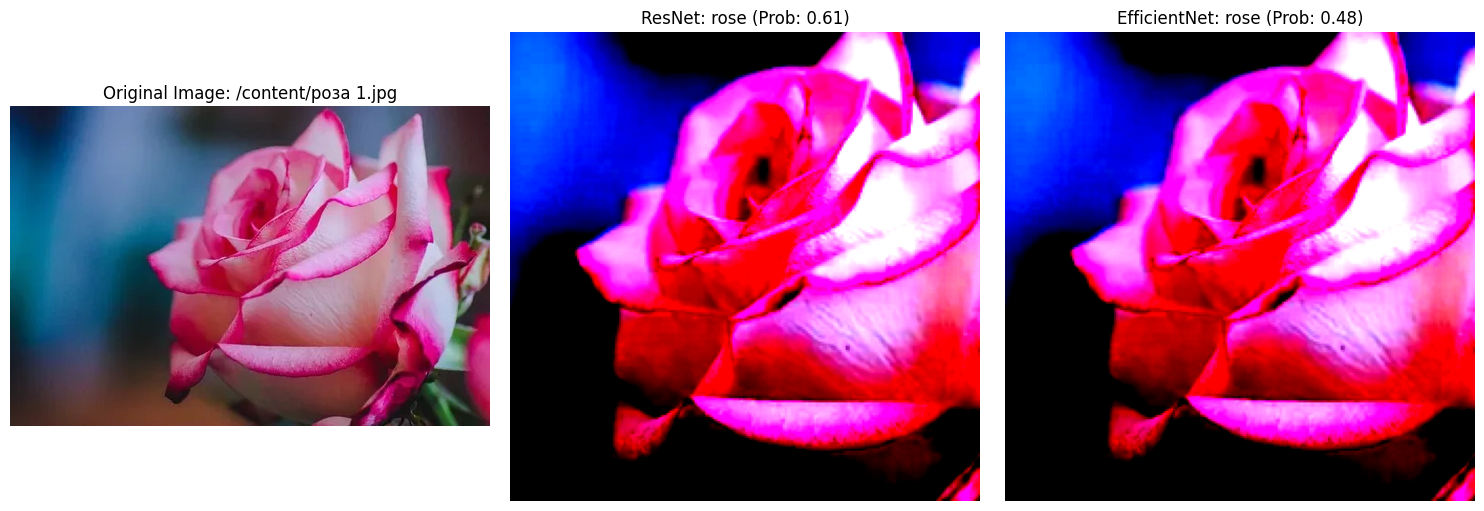

In [ ]:
def compare_models(model1, model2, image_paths, transform):
    model1.eval()
    model2.eval()
    num_images = len(image_paths)
    fig, axes = plt.subplots(num_images, 3, figsize=(15, 5 * num_images))

    # Если изображение одно, axes будет одномерным
    if num_images == 1:
        axes = axes.reshape(1, -1)  # Преобразуем axes в двумерный массив

    for i, img_path in enumerate(image_paths):
        # Загрузка и преобразование изображения
        img = Image.open(img_path)
        img_transformed = transform(img).unsqueeze(0).to(device)

        # Предсказание первой модели
        with torch.no_grad():
            output1 = model1(img_transformed)
            probs1 = F.softmax(output1, dim=1)
            _, preds1 = torch.max(probs1, 1)

        # Предсказание второй модели
        with torch.no_grad():
            output2 = model2(img_transformed)
            probs2 = F.softmax(output2, dim=1)
            _, preds2 = torch.max(probs2, 1)


        print(f"Image: {img_path}")
        print(f"ResNet Predicted Class: {class_names[preds1.item()]}, Probability: {probs1[0][preds1].item():.2f}")
        print(f"EfficientNet Predicted Class: {class_names[preds2.item()]}, Probability: {probs2[0][preds2].item():.2f}")
        print("-" * 40)

        # Визуализация исходного изображения
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f'Original Image: {img_path}')
        axes[i, 0].axis('off')

        # Визуализация преобразованного изображения для ResNet
        img_transformed1 = img_transformed.squeeze().cpu().numpy().transpose((1, 2, 0))
        img_transformed1 = np.clip(img_transformed1, 0, 1)
        axes[i, 1].imshow(img_transformed1)
        axes[i, 1].set_title(f'ResNet: {class_names[preds1.item()]} (Prob: {probs1[0][preds1].item():.2f})')
        axes[i, 1].axis('off')

        # Визуализация преобразованного изображения для EfficientNet
        img_transformed2 = img_transformed.squeeze().cpu().numpy().transpose((1, 2, 0))
        img_transformed2 = np.clip(img_transformed2, 0, 1)
        axes[i, 2].imshow(img_transformed2)
        axes[i, 2].set_title(f'EfficientNet: {class_names[preds2.item()]} (Prob: {probs2[0][preds2].item():.2f})')
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

# Сравнение моделей
compare_models(model_resnet, model_efficientnet, new_image_paths, data_transforms['val'])

Image: /content/роза 2.jpg
ResNet Predicted Class: rose, Probability: 0.6866
EfficientNet Predicted Class: rose, Probability: 0.3945
----------------------------------------


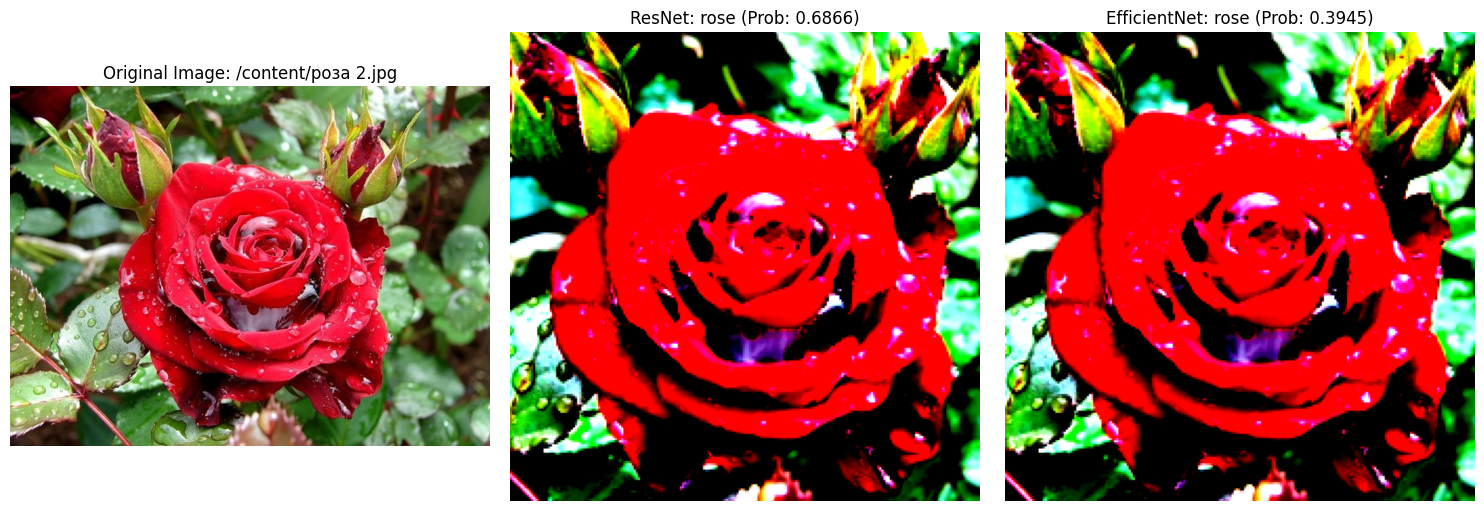

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import Image  # Для работы с изображениями
import numpy as np

# Функция для сравнения предсказаний двух моделей
def compare_models_on_new_image(model1, model2, image_path, transform):
    # Загрузка изображения
    img = Image.open(image_path)

    # Применение преобразований
    img_transformed = transform(img).unsqueeze(0).to(device)

    # Переводим модели в режим оценки
    model1.eval()
    model2.eval()

    # Предсказание первой модели (ResNet)
    with torch.no_grad():
        output1 = model1(img_transformed)
        probs1 = F.softmax(output1, dim=1)
        _, preds1 = torch.max(probs1, 1)

    # Предсказание второй модели (EfficientNet)
    with torch.no_grad():
        output2 = model2(img_transformed)
        probs2 = F.softmax(output2, dim=1)
        _, preds2 = torch.max(probs2, 1)

    # Вывод предсказаний в консоль
    print(f"Image: {image_path}")
    print(f"ResNet Predicted Class: {class_names[preds1.item()]}, Probability: {probs1[0][preds1].item():.4f}")
    print(f"EfficientNet Predicted Class: {class_names[preds2.item()]}, Probability: {probs2[0][preds2].item():.4f}")
    print("-" * 40)

    # Визуализация
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Исходное изображение
    axes[0].imshow(img)
    axes[0].set_title(f'Original Image: {image_path}')
    axes[0].axis('off')

    # Преобразованное изображение для ResNet
    img_transformed1 = img_transformed.squeeze().cpu().numpy().transpose((1, 2, 0))
    img_transformed1 = np.clip(img_transformed1, 0, 1)
    axes[1].imshow(img_transformed1)
    axes[1].set_title(f'ResNet: {class_names[preds1.item()]} (Prob: {probs1[0][preds1].item():.4f})')
    axes[1].axis('off')

    # Преобразованное изображение для EfficientNet
    img_transformed2 = img_transformed.squeeze().cpu().numpy().transpose((1, 2, 0))
    img_transformed2 = np.clip(img_transformed2, 0, 1)
    axes[2].imshow(img_transformed2)
    axes[2].set_title(f'EfficientNet: {class_names[preds2.item()]} (Prob: {probs2[0][preds2].item():.4f})')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# Путь к новому изображению
new_image_path = '/content/роза 2.jpg'  # Замените на путь к вашему изображению

# Сравнение моделей на новом изображении
compare_models_on_new_image(model_resnet, model_efficientnet, new_image_path, data_transforms['val'])

Image: /content/лилия 1.jpg
ResNet Predicted Class: sunflower, Probability: 0.8757
EfficientNet Predicted Class: rose, Probability: 0.3858
----------------------------------------


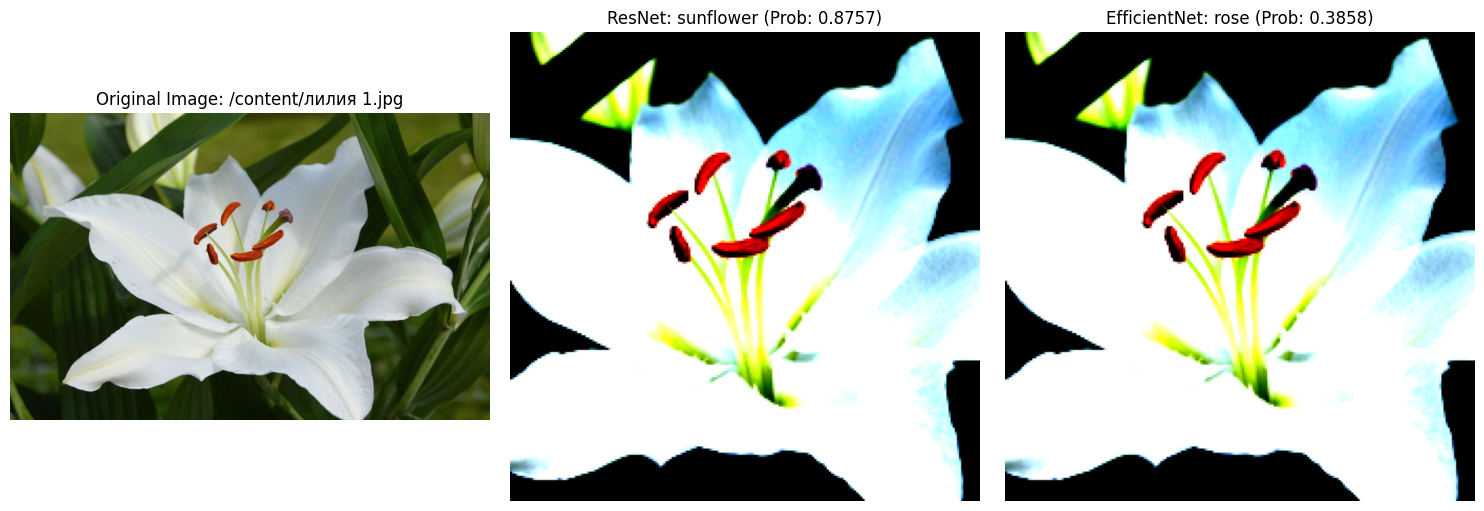

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import Image  # Для работы с изображениями
import numpy as np

# Функция для сравнения предсказаний двух моделей
def compare_models_on_new_image(model1, model2, image_path, transform):
    # Загрузка изображения
    img = Image.open(image_path)

    # Применение преобразований
    img_transformed = transform(img).unsqueeze(0).to(device)

    # Переводим модели в режим оценки
    model1.eval()
    model2.eval()

    # Предсказание первой модели (ResNet)
    with torch.no_grad():
        output1 = model1(img_transformed)
        probs1 = F.softmax(output1, dim=1)
        _, preds1 = torch.max(probs1, 1)

    # Предсказание второй модели (EfficientNet)
    with torch.no_grad():
        output2 = model2(img_transformed)
        probs2 = F.softmax(output2, dim=1)
        _, preds2 = torch.max(probs2, 1)

    # Вывод предсказаний в консоль
    print(f"Image: {image_path}")
    print(f"ResNet Predicted Class: {class_names[preds1.item()]}, Probability: {probs1[0][preds1].item():.4f}")
    print(f"EfficientNet Predicted Class: {class_names[preds2.item()]}, Probability: {probs2[0][preds2].item():.4f}")
    print("-" * 40)

    # Визуализация
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Исходное изображение
    axes[0].imshow(img)
    axes[0].set_title(f'Original Image: {image_path}')
    axes[0].axis('off')

    # Преобразованное изображение для ResNet
    img_transformed1 = img_transformed.squeeze().cpu().numpy().transpose((1, 2, 0))
    img_transformed1 = np.clip(img_transformed1, 0, 1)
    axes[1].imshow(img_transformed1)
    axes[1].set_title(f'ResNet: {class_names[preds1.item()]} (Prob: {probs1[0][preds1].item():.4f})')
    axes[1].axis('off')

    # Преобразованное изображение для EfficientNet
    img_transformed2 = img_transformed.squeeze().cpu().numpy().transpose((1, 2, 0))
    img_transformed2 = np.clip(img_transformed2, 0, 1)
    axes[2].imshow(img_transformed2)
    axes[2].set_title(f'EfficientNet: {class_names[preds2.item()]} (Prob: {probs2[0][preds2].item():.4f})')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# Путь к новому изображению
new_image_path = '/content/лилия 1.jpg'  # Замените на путь к вашему изображению

# Сравнение моделей на новом изображении
compare_models_on_new_image(model_resnet, model_efficientnet, new_image_path, data_transforms['val'])

In [ ]:
from duckduckgo_search import DDGS  # импотр модуля

with DDGS() as ddgs:
    ddgs_images_gen = ddgs.images(
      'dog',  # пример получения изображений по запросу 'dog'
      region="wt-wt",
      size="Medium",
      type_image="photo",
      max_results=30,  # максимальное количество изображений в ответе
    )
    with open('dog.txt', 'w') as f:  # пишем в файл полученные ссылки на изображения для скачивания
      for r in ddgs_images_gen:
        f.write(f"{r['image']}\n")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!mkdir "/content/drive/My Drive/data"

In [ ]:
#  содержимое файла со ссылками
!cat dog.txt

In [ ]:
# утилита wget построчно читает файл dog.txt и скачивает по URL файлы в папку,
# указанную после флага -P. --random-wait добавляет случайные интервалы между запросами,
# чтобы снизить вероятность блокировки

!wget -i dog.txt --random-wait -P "/content/drive/My Drive/data/dog"

#
В результате работы по этому разделу должен получиться датасет.
Проверьте что все скачанные изображения открываются и удалите поврежденные файлы. Изображения необходимо разделить в папках на train и test.